In [110]:
import pandas as pd
import numpy as np

In [111]:
df1 = pd.read_csv(r"chennai_house_market_data_1.csv")

# Missing Value Handling
Missing values were identified and treated using locality-specific imputation wherever appropriate. After preprocessing, no missing values remained in the dataset.

In [112]:
missing_before = df1.isnull().sum()
missing_before[missing_before > 0]

bathroom    1217
age          891
dtype: int64

In [113]:
"""Replacing the missing values of bathroom with mean of number bathrooms in other houses of their locality"""

bathroom_means = df1.groupby("location")["bathroom"].mean()
df1.loc[df1["bathroom"].isna(), "bathroom"] = (
    df1.loc[df1["bathroom"].isna(), "location"].map(bathroom_means)
)

""" global fallback for locations with no Non-missing Value """
df1 = df1.fillna({"bathroom": df1["bathroom"].median()})

In [114]:
df1['bathroom'].isna().sum()

np.int64(0)

In [115]:

df1['age'].isna().sum()

np.int64(891)

In [116]:
"""Replacing the missing values of age with mean of house age in their locality"""

age_means = df1.groupby("location")["age"].mean()
df1.loc[df1["age"].isna(), "age"] = (
    df1.loc[df1["age"].isna(), "location"].map(age_means)
)

""" global fallback for locations with no Non-missing Value """
df1 = df1.fillna({"age": df1["age"].median()})

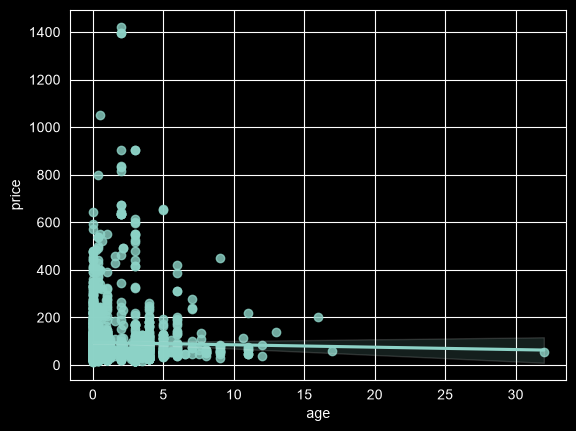

In [117]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.regplot(data=df1, x="age", y="price")
plt.show()

In [118]:
print(df1[["age", "price"]].corr().loc['age','price'])

-0.017452005107973696


## Age Feature Handling
The age feature contained 891 missing values out of 2620 records (approximately 34% missing). Missing values were initially imputed using the mean house age within each locality. However, further analysis showed that age had a very weak relationship with price (correlation = -0.018).

To evaluate its usefulness, a model was trained both with and without the age feature. The model without age achieved slightly better performance, indicating that the feature contributed little predictive value while introducing additional complexity. Therefore, the age feature was removed from the final model.
- ### With Age
    - RMSE = 27.30
    - R² = 0.9440

- ### Without Age
    - RMSE = 27.23
    - R² = 0.9443

The model without the age feature achieved slightly better performance while eliminating a feature with
approximately 34% missing values. Therefore, age was excluded from the final model.

In [119]:
df1['age'].isna().sum()

np.int64(0)

In [120]:
missing_before = df1.isnull().sum()
missing_before[missing_before > 0]

Series([], dtype: int64)

In [121]:
df1[['bathroom', 'age']].dtypes

bathroom    float64
age         float64
dtype: object

In [122]:
df1['bathroom'] = df1['bathroom'].astype('int64')
df1['age'] = df1['age'].astype('int64')

In [123]:
df1[['bathroom', 'age']].dtypes

bathroom    int64
age         int64
dtype: object

In [124]:
df1.to_csv(r"preprocessed_data_outliers_not_removed.csv", index=False)

In [125]:
print("Final Dataset Shape:", df1.shape)
print("\nData Types:")
print(df1.dtypes)

Final Dataset Shape: (2620, 8)

Data Types:
price       float64
area          int64
status          str
bhk           int64
bathroom      int64
age           int64
location        str
builder         str
dtype: object


# Final Preprocessed Dataset1
The final dataset1 contains cleaned, imputed records ready for model training. No-outliers removed

# Outlier Treatment
Outliers were identified using price per square foot and removed using the IQR method. This reduced the influence of extreme property listings.

In [126]:
# Outlier detection
df2 = df1.copy()
df2["price_per_sqft"] = df2["price"] / df2["area"]

# Remove extreme outliers using IQR
Q1 = df2["price_per_sqft"].quantile(0.25)
Q3 = df2["price_per_sqft"].quantile(0.75)
IQR = Q3 - Q1
df2 = df2[(df2["price_per_sqft"] >= Q1 - 1.5*IQR) & (df2["price_per_sqft"] <= Q3 + 1.5*IQR)]


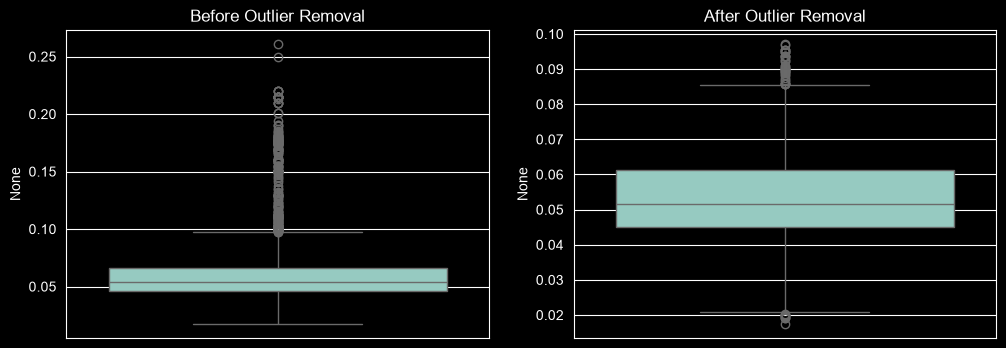

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df1["price"] / df1["area"], ax=ax[0])
ax[0].set_title("Before Outlier Removal")

sns.boxplot(y=df2["price"] / df2["area"], ax=ax[1])
ax[1].set_title("After Outlier Removal")

plt.show()

In [128]:
df2 = df2.drop(columns=["price_per_sqft"])

# Temporary feature
A new feature called Price Per Square Foot was temporarily created to identify anomalous property records. This feature was used exclusively for outlier detection and removed afterwards to avoid data leakage into the machine learning model.

In [129]:
rows_removed = len(df1) - len(df2)

print("Rows before:", len(df1))
print("Rows after :", len(df2))
print("Rows removed:", rows_removed)

print(
    f"Percentage removed: {(rows_removed / len(df1))*100:.2f}%"
)

Rows before: 2620
Rows after : 2311
Rows removed: 309
Percentage removed: 11.79%


In [130]:
df2.to_csv(r"preprocessed_data_outliers_removed.csv", index=False)

In [131]:
print("Final Dataset Shape:", df2.shape)
print("\nData Types:")
print(df2.dtypes)

Final Dataset Shape: (2311, 8)

Data Types:
price       float64
area          int64
status          str
bhk           int64
bathroom      int64
age           int64
location        str
builder         str
dtype: object


# Final Preprocessed Dataset2
The final dataset2 contains cleaned, imputed, and outlier-filtered records ready for model training.